<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/Hierarchical_Clustering_my_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HIERARCHICAL CLUSTERING (with libraries, paper-ready)
**Edit only the ✏️ DATA cell.** Two input styles are covered: **(A) points** (x, y) or **(B) a distance matrix** given on paper.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
pd.set_option('display.width', 200)

## ✏️ DATA (A): points

In [2]:
points = {'A':(1,1), 'B':(1.5,1.5), 'C':(5,5), 'D':(3,4), 'E':(4,4), 'F':(3,3.5)}
METHOD = 'single'       # 'single' (min) | 'complete' (max) | 'average' | 'ward'
N_CLUSTERS = 2          # where to cut the tree

names = list(points)
X = np.array([points[n] for n in names], dtype=float)
dist = pd.DataFrame(squareform(pdist(X)), index=names, columns=names).round(3)
print('Euclidean distance matrix:'); dist

Euclidean distance matrix:


,A,B,C,D,E,F
A,0.000,0.707,5.657,3.606,4.243,3.202
B,0.707,0.000,4.950,2.915,3.536,2.500
C,5.657,4.950,0.000,2.236,1.414,2.500
D,3.606,2.915,2.236,0.000,1.000,0.500
E,4.243,3.536,1.414,1.000,0.000,1.118
F,3.202,2.500,2.500,0.500,1.118,0.000


### ✏️ DATA (B): the paper gives a distance matrix instead? Use this cell and skip (A)

In [3]:
USE_MATRIX = False
if USE_MATRIX:
    names = ['P1','P2','P3','P4','P5']
    M = np.array([[0,  9,  3,  6, 11],
                  [9,  0,  7,  5, 10],
                  [3,  7,  0,  9,  2],
                  [6,  5,  9,  0,  8],
                  [11,10,  2,  8,  0]], dtype=float)
    dist = pd.DataFrame(M, index=names, columns=names)
    X = None
    print(dist)

## 1. Linkage table: which clusters merge, at what distance

In [4]:
Z = linkage(squareform(dist.values, checks=False), method=METHOD)   # works for both A and B

members = {i: [names[i]] for i in range(len(names))}
rows = []
for step, (a, b, d, size) in enumerate(Z, start=1):
    a, b = int(a), int(b)
    new = len(names) + step - 1
    members[new] = members[a] + members[b]
    rows.append([step, '{'+','.join(members[a])+'}', '{'+','.join(members[b])+'}', round(d, 3), int(size)])
pd.DataFrame(rows, columns=['Step','Cluster 1','Cluster 2','Merge distance','New size'])

,Step,Cluster 1,Cluster 2,Merge distance,New size
0,1,{D},{F},0.500,2
1,2,{A},{B},0.707,2
2,3,{E},"{D,F}",1.000,3
3,4,{C},"{E,D,F}",1.414,4
4,5,"{A,B}","{C,E,D,F}",2.500,6


## 2. Dendrogram
Cut the tree with a horizontal line → the vertical lines it crosses are the clusters.

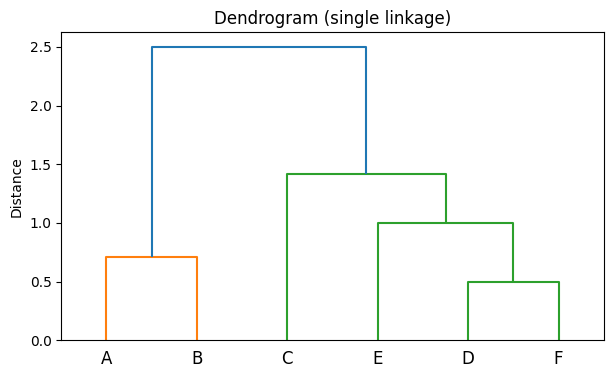

In [5]:
plt.figure(figsize=(7,4))
dendrogram(Z, labels=names)
plt.title(f'Dendrogram ({METHOD} linkage)'); plt.ylabel('Distance'); plt.show()

## 3. Cut into clusters

In [6]:
labels = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
for c in sorted(set(labels)):
    print(f'Cluster {c}:', [n for n, l in zip(names, labels) if l == c])

Cluster 1: ['A', 'B']
Cluster 2: ['C', 'D', 'E', 'F']


## 4. Compare linkage methods (same data, different trees)

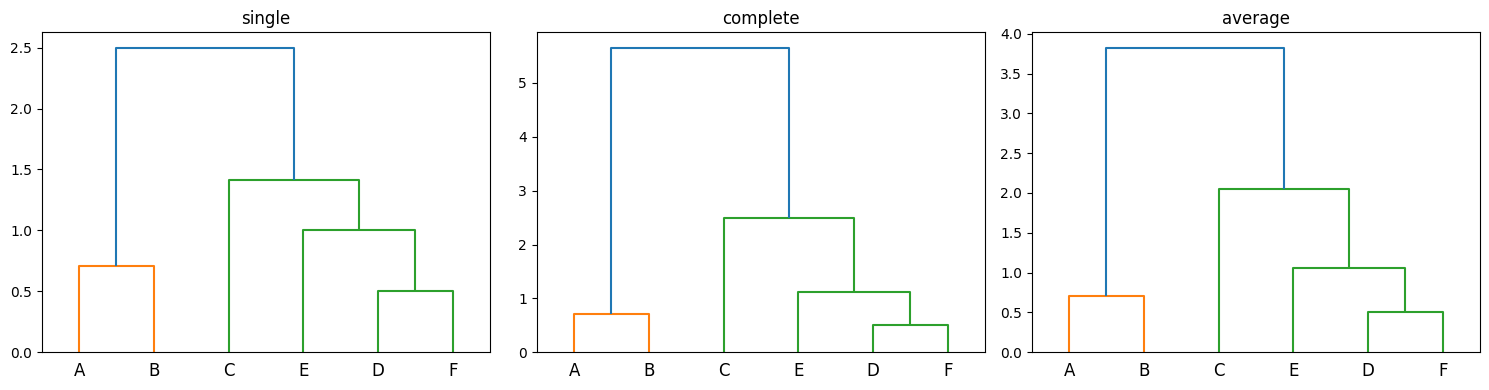

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, m in zip(axes, ['single','complete','average']):
    dendrogram(linkage(squareform(dist.values, checks=False), method=m), labels=names, ax=ax)
    ax.set_title(m)
plt.tight_layout(); plt.show()

## 5. Same thing with `sklearn` (only for point data, not a distance matrix)

In [8]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
if X is not None:
    sk_link = METHOD   # sklearn supports ward, complete, average, single
    ag = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage=sk_link).fit(X)
    print('Labels:', {n: int(l) + 1 for n, l in zip(names, ag.labels_)})
    if 1 < N_CLUSTERS < len(X): print('Silhouette:', round(silhouette_score(X, ag.labels_), 3))

Labels: {'A': 2, 'B': 2, 'C': 1, 'D': 1, 'E': 1, 'F': 1}
Silhouette: 0.679


**Viva:** Agglomerative = bottom-up (merge closest), divisive = top-down.
Single = **min** distance between clusters (chaining problem), complete = **max**, average = mean of all pairs, ward = least increase in variance.
No need to fix k in advance; the dendrogram shows all possible k.